# 1. Problem

Recover the position and orientation of 432 shuffled square RGB fragments.
These are synthetic cut-and-scramble observations of an author-provided real
photograph, rather than measurements of physically broken objects.

For a processed image $X$, grid block extraction $B_p$, and exact
counterclockwise quarter-turn $R_s$,
$$
Y_i=R_{s_i}B_{p_i}X,\qquad q_i=-s_i\pmod4.
$$
Index $i$ follows public tile order. Positions $p_i$ have row/column units of
grid cells; $q_i$ is a dimensionless correcting quarter-turn applied to the
observed tile. All 432 tiles are present. A common global C4 action is allowed;
reflection and independent orientation/position alignment are not.

This notebook actively executes the complete cleaned initialization and five
refinements. Original source results are loaded only as identified comparisons.
Actual acquisition poses are used only for evaluation and image rendering.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import scipy,matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
TASK=Path.cwd()
if not (TASK/'src').is_dir():TASK=TASK.parent
sys.path.insert(0,str(TASK))
from src.preprocessing import load_data,compute_mgc
from src.main import reconstruct
from src.generate_data import acquire,adjoint
from src.visualization import compare_poses,render_tiles,dynamic_range_nrmse,plot_reconstructions
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
tiles=load_data(TASK/'data/raw_data.npz')
with np.load(TASK/'evaluation/ground_truth.npz',allow_pickle=False) as z:
    truth_p=z['positions'][0];truth_q=z['quarter_turns'][0]
with np.load(TASK/'notebooks/reference_outputs/upstream_pose_history.npz',allow_pickle=False) as z:
    upstream={k:z[k] for k in z.files}
truth_image=render_tiles(tiles,truth_p,truth_q)
assert np.array_equal(acquire(truth_image,truth_p,truth_q),tiles)
print('Native observations:',tiles.shape,tiles.dtype,'range',int(tiles.min()),int(tiles.max()))
print('Executed interpreter:',sys.executable)
print('Runtime versions:',sys.version.split()[0],np.__version__,scipy.__version__,matplotlib.__version__)
print('Known geometry: 18 x 24 grid; 28 x 28 RGB pixels per tile; no added noise.')


Native observations: (432, 28, 28, 3) uint16 range 0 65535
Executed interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Runtime versions: 3.11.11 2.4.6 1.17.1 3.11.1
Known geometry: 18 x 24 grid; 28 x 28 RGB pixels per tile; no added noise.


# 2. Data

The public input is only uint16 tiles with batch-first shape
$(1,432,28,28,3)$. RGB code values are retained without radiance conversion or
channel fitting. The original processed canvas is 504 by 672 pixels.
The display mosaic below uses public observation order and zero correcting
rotation; it is not an inverse reconstruction. The complete image is rendered
from actual known acquisition poses and is explicitly labeled truth.
For RGB display only, native values are divided by 65535.

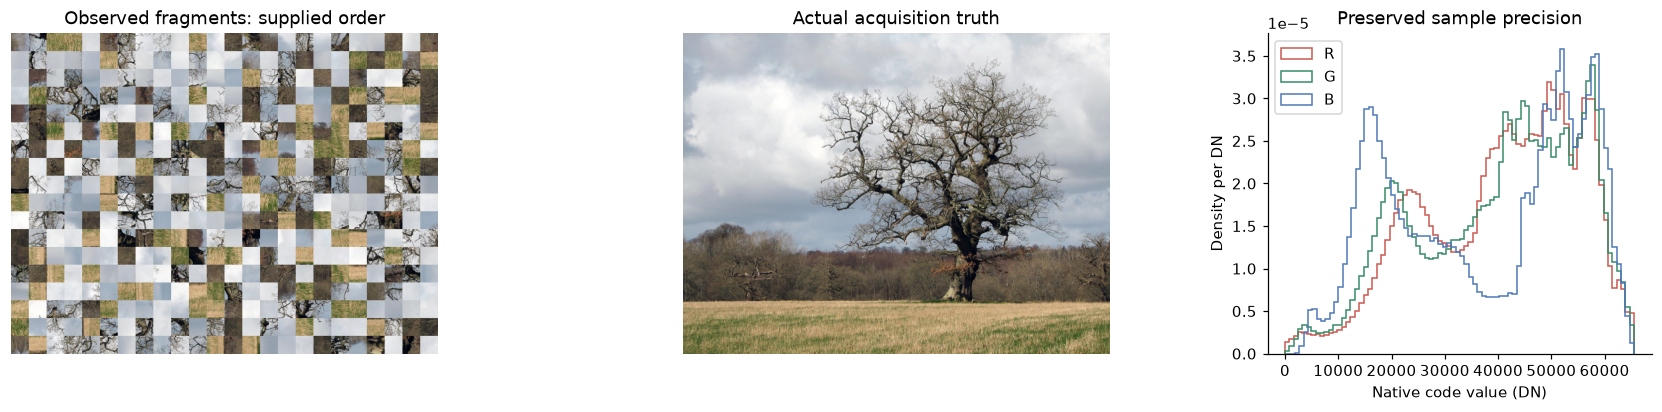

In [2]:
observation_p=np.array([(i//24,i%24) for i in range(432)],np.int64)
observation_canvas=render_tiles(tiles,observation_p,np.zeros(432,np.int64))
fig,ax=plt.subplots(1,3,figsize=(16,4),gridspec_kw={'width_ratios':[1.25,1.25,.8]})
ax[0].imshow(observation_canvas.astype(float)/65535);ax[0].set_title('Observed fragments: supplied order')
ax[1].imshow(truth_image.astype(float)/65535);ax[1].set_title('Actual acquisition truth')
for a in ax[:2]:a.set_axis_off()
for c,color in enumerate(['#cc5a52','#388b68','#4f79b8']):
    ax[2].hist(tiles[...,c].ravel(),bins=80,histtype='step',color=color,label='RGB'[c],density=True)
ax[2].set(xlabel='Native code value (DN)',ylabel='Density per DN',title='Preserved sample precision');ax[2].legend()
fig.tight_layout();plt.show()


# 3. Physics and mathematical checks

Block extraction followed by a permutation and C4 rotations is a pixel
permutation: it preserves norm and has an exact inverse for a complete pose.
For floating arrays, its adjoint is rotated overlap-add. No noise or missing
pixels are created by the bound acquisition.

Boundary matching uses one-pixel RGB gradients and covariance statistics. For
seam difference $x_t$ at pixel $t$, edge means $\mu_i,\mu_j$ in DN and
covariances $C_i,C_j$ in DN squared, compatibility is dimensionless:
$$
d(i,j)=\sum_{t=1}^{28}\left[
\sqrt{(x_t-\mu_j)^TC_j^{-1}(x_t-\mu_j)}
+\sqrt{(-x_t-\mu_i)^TC_i^{-1}(-x_t-\mu_i)}\right].
$$
The source's nine augmentation rows and sample-covariance convention are
preserved. Explicit positive-definite Cholesky whitening evaluates the quadratic forms without a domain solver.

The independent tests cover the adjoint identity, full pixel roundtrip,
covariance positivity, all sixteen relative rotation channels, and C4 gauge.
They supplement original-code parity rather than replacing it.

Adjoint relative residual: 8.643107017178835e-14


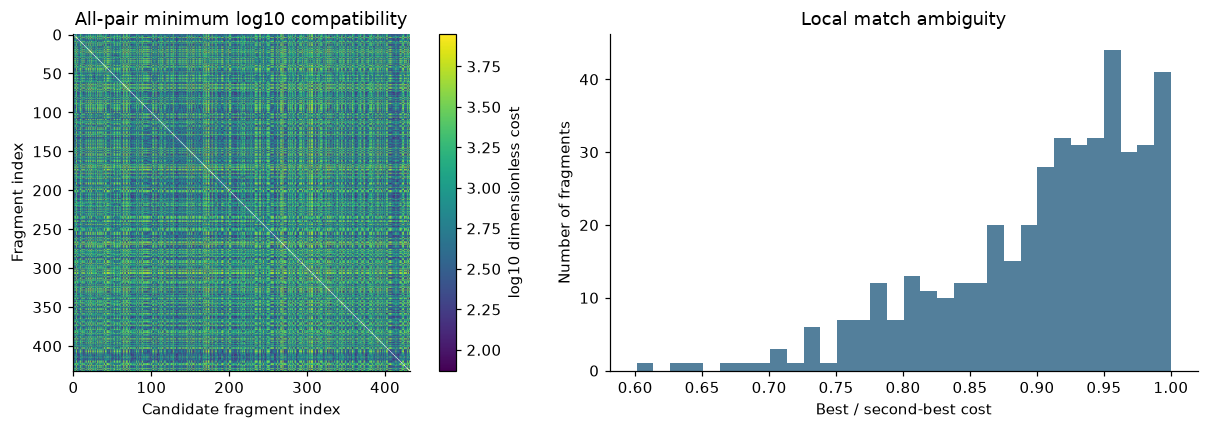

In [3]:
assert truth_image.dtype==np.uint16
assert np.array_equal(adjoint(tiles,truth_p,truth_q),truth_image)
# Independent floating probe tests the general linear adjoint, with fixed analytic values.
probe=np.sin(np.arange(tiles.size,dtype=float)).reshape(tiles.shape)
scene=truth_image.astype(float)/65535
lhs=np.vdot(acquire(scene,truth_p,truth_q),probe)
rhs=np.vdot(scene,adjoint(probe,truth_p,truth_q))
print('Adjoint relative residual:',abs(lhs-rhs)/max(1,abs(lhs),abs(rhs)))
scores=compute_mgc(tiles)
assert scores.dtype==np.float32 and np.count_nonzero(np.isposinf(scores))==432*16
best=np.min(scores,axis=2)
finite=best[np.isfinite(best)]
fig,ax=plt.subplots(1,2,figsize=(12,4))
im=ax[0].imshow(np.ma.masked_invalid(np.log10(best)),cmap='viridis',rasterized=True)
ax[0].set(xlabel='Candidate fragment index',ylabel='Fragment index',title='All-pair minimum log10 compatibility')
fig.colorbar(im,ax=ax[0],label='log10 dimensionless cost')
ordered=np.sort(scores.reshape(432,-1),axis=1)
ratio=ordered[:,0]/ordered[:,1]
ax[1].hist(ratio,bins=32,color='#537f9b');ax[1].set(xlabel='Best / second-best cost',ylabel='Number of fragments',title='Local match ambiguity')
fig.tight_layout();plt.show()


# 4. Method

A graph combines boundary-derived relative quarter-turn proposals, tested
nearest neighbors, two-hop overlap and four-edge cycle consistency. With complex
connection $T$, nonnegative weight matrix $W$, degree matrix
$D_{ii}=\sum_j|W_{ij}T_{ij}|$, synchronization uses the minimum left singular
mode of
$$
D^{-1/2}(D-W\odot T)D^{-1/2}.
$$
Its phase is rounded to C4. The source requests five smallest singular triplets
in descending order and takes the final returned column, namely the smallest
mode. The local general SVD backend implements that meaning explicitly.

Already oriented fragments enter a weighted L1 displacement relaxation.
Its free row/column coordinates, nonnegative residual slacks, unit neighbor
displacements and translation anchor are assembled locally. Connected blocks,
greedy joining, cropping and hole filling produce a discrete grid. Both global
90-degree alternatives run at every stage. Five refinements update connection
evidence from the current assembly.

The following cell computes all six stages fresh using only public observations.
It does not load source scores, a historical assembly, truth or a seed as an
initialization. Original source poses below are frozen independent comparison
measurements. Native execution failures and documented compatibility changes
remain in the validation record; they are not described as unchanged source.

The shipped explicit-spd-v1.2 numerical backend evaluates each real RGB covariance quadratic form by double-precision Cholesky whitening. For a covariance $C$ in DN squared and residual $u$ in DN, let $L$ be lower triangular with positive diagonal:
$$
C=LL^T,\qquad z=L^{-1}u,\qquad M(u,C)=z_0^2+z_1^2+z_2^2.
$$
Here $L$ has DN units and $z,M$ are dimensionless. The scalar three-by-three factorization and forward substitution are implemented explicitly; no negative value is clipped. Finite, symmetry and positive-pivot guards reject invalid inputs, and the original negative-quadratic guard remains. Full original float32 MGC scores are bitwise identical. The earlier owned-input-only experiment still failed an additional CLI and was rejected; original failures, native access violation and finite stability checks remain archived without an asserted native root cause.


Execution is isolated from the plotting kernel: an inline child script uses the same Python interpreter to call the cleaned reconstruction once from public raw tiles, with initialization and all five refinements. It returns freshly computed poses and all six stage records through temporary NPZ files, and the independent Judge evaluates that fresh submission. No truth, seed, cached score or historical assembly is passed to the child. The files are removed after loading; this is active reconstruction, not a cache preview. A recorded direct-kernel indexing failure could not be reproduced in two exception-only private probes; its native cause is not claimed.


In [4]:
import os,subprocess,tempfile
child_script=r"""
import sys,time,json,hashlib
from pathlib import Path
import numpy as np
from src.preprocessing import load_data
from src.main import reconstruct
raw,pose_path,history_path=map(Path,sys.argv[1:])
started=time.perf_counter()
p,q,history=reconstruct(load_data(raw),progress=lambda h:print('Fresh child completed stage',h['stage'],'costs',h['costs'],'branch',h['selected_branch'],flush=True))
elapsed=time.perf_counter()-started
np.savez_compressed(pose_path,positions=p[None],quarter_turns=q[None])
payload={'stages':np.arange(len(history),dtype=np.int64),'fresh_seconds':np.array(elapsed),'raw_sha256':np.array(hashlib.sha256(raw.read_bytes()).hexdigest())}
for h in history:
    prefix=f"stage{h['stage']}_"
    for key in ['positions','quarter_turns','goal','costs','source_rot_nums']:
        payload[prefix+key]=h[key]
    payload[prefix+'selected_branch']=np.array(h['selected_branch'],np.int64)
    payload[prefix+'elapsed_seconds']=np.array(h['elapsed_seconds'])
    payload[prefix+'lp_trace_json']=np.array(json.dumps(h['lp_trace'],allow_nan=False))
np.savez_compressed(history_path,**payload)
print('ACTIVE_CLEANED_CHILD_SUCCESS',sys.executable,'seconds',elapsed,'rawSHA',payload['raw_sha256'],flush=True)
"""
child_env=dict(os.environ,OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',NUMEXPR_NUM_THREADS='1',PYTHONIOENCODING='utf-8',MPLBACKEND='Agg')
with tempfile.TemporaryDirectory(prefix='imaging101_gcl_active_') as directory:
    temp=Path(directory);submission=temp/'fresh_submission.npz';history_file=temp/'fresh_history.npz';report=temp/'fresh_judge.json'
    command=[sys.executable,'-c',child_script,str((TASK/'data/raw_data.npz').resolve()),str(submission),str(history_file)]
    completed=subprocess.run(command,cwd=TASK,env=child_env,capture_output=True,text=True,encoding='utf-8',timeout=180)
    print(completed.stdout)
    if completed.returncode!=0:raise RuntimeError('Fresh reconstruction child failed: '+completed.stderr)
    with np.load(submission,allow_pickle=False) as z:
        positions=z['positions'][0].copy();quarter_turns=z['quarter_turns'][0].copy()
    with np.load(history_file,allow_pickle=False) as z:
        fresh_seconds=float(z['fresh_seconds']);child_raw_sha=str(z['raw_sha256'].item());history=[]
        for stage in z['stages']:
            stage=int(stage);prefix=f'stage{stage}_'
            h={'stage':stage,'selected_branch':int(z[prefix+'selected_branch']),'elapsed_seconds':float(z[prefix+'elapsed_seconds']),'lp_trace':json.loads(str(z[prefix+'lp_trace_json'].item()))}
            for key in ['positions','quarter_turns','goal','costs','source_rot_nums']:h[key]=z[prefix+key].copy()
            history.append(h)
    judged=subprocess.run([sys.executable,'-I',str(TASK/'evaluation/judge.py'),'--prediction',str(submission),'--report',str(report)],cwd=temp,env=child_env,capture_output=True,text=True,encoding='utf-8',timeout=30)
    fresh_judge_report=json.loads(report.read_text(encoding='utf-8'))
    print('Fresh child submission Judge:',judged.returncode,fresh_judge_report['metrics'])
    assert judged.returncode==0 and fresh_judge_report['passed'],judged.stderr
assert not temp.exists()
assert len(history)==6 and all(len(h['lp_trace'])==2 for h in history)
fresh_report=compare_poses(positions,quarter_turns,truth_p,truth_q)
fresh_image=render_tiles(tiles,fresh_report['aligned_positions'],fresh_report['aligned_quarter_turns'])
print('Fresh full path seconds:',fresh_seconds,'input SHA256:',child_raw_sha)
print(json.dumps(fresh_report['metrics'],indent=2))
print('Dynamic-range image NRMSE:',dynamic_range_nrmse(fresh_image,truth_image))
assert fresh_report['passed']


Fresh child completed stage 0 costs [190180.921875 190128.484375] branch 1
Fresh child completed stage 1 costs [190211.3125   190180.921875] branch 1
Fresh child completed stage 2 costs [190180.921875 190128.484375] branch 1
Fresh child completed stage 3 costs [190128.484375 190159.03125 ] branch 0
Fresh child completed stage 4 costs [190128.484375 190159.03125 ] branch 0
Fresh child completed stage 5 costs [190128.484375 190159.03125 ] branch 0
ACTIVE_CLEANED_CHILD_SUCCESS D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe seconds 4.488984300056472 rawSHA 04609aea0476b71683ab7e51a744b22a9448f4f81a61e8e5aaa3c60cdfc8c84c

Fresh child submission Judge: 0 {'position_accuracy': 1.0, 'orientation_accuracy': 1.0, 'joint_piece_accuracy': 1.0, 'neighbor_accuracy': 1.0, 'oriented_neighbor_accuracy': 1.0}
Fresh full path seconds: 4.488984300056472 input SHA256: 04609aea0476b71683ab7e51a744b22a9448f4f81a61e8e5aaa3c60cdfc8c84c
{
  "position_accuracy": 1.0,
  "orient

# 5. Results

All comparisons use one common global quarter-turn for positions and physical
orientations. Joint-piece accuracy requires both quantities to be correct.
Oriented-neighbor accuracy requires the correct directed displacement and both
tile orientations on each true seam. The two frozen acceptance boundaries are
0.95. The complete image NRMSE is RMS code-value error divided by the actual
truth's code-value dynamic range; it is a diagnostic, not a mechanical zero
acceptance threshold. The image error panel uses original DN, without a fitted
brightness, crop or channel transform.

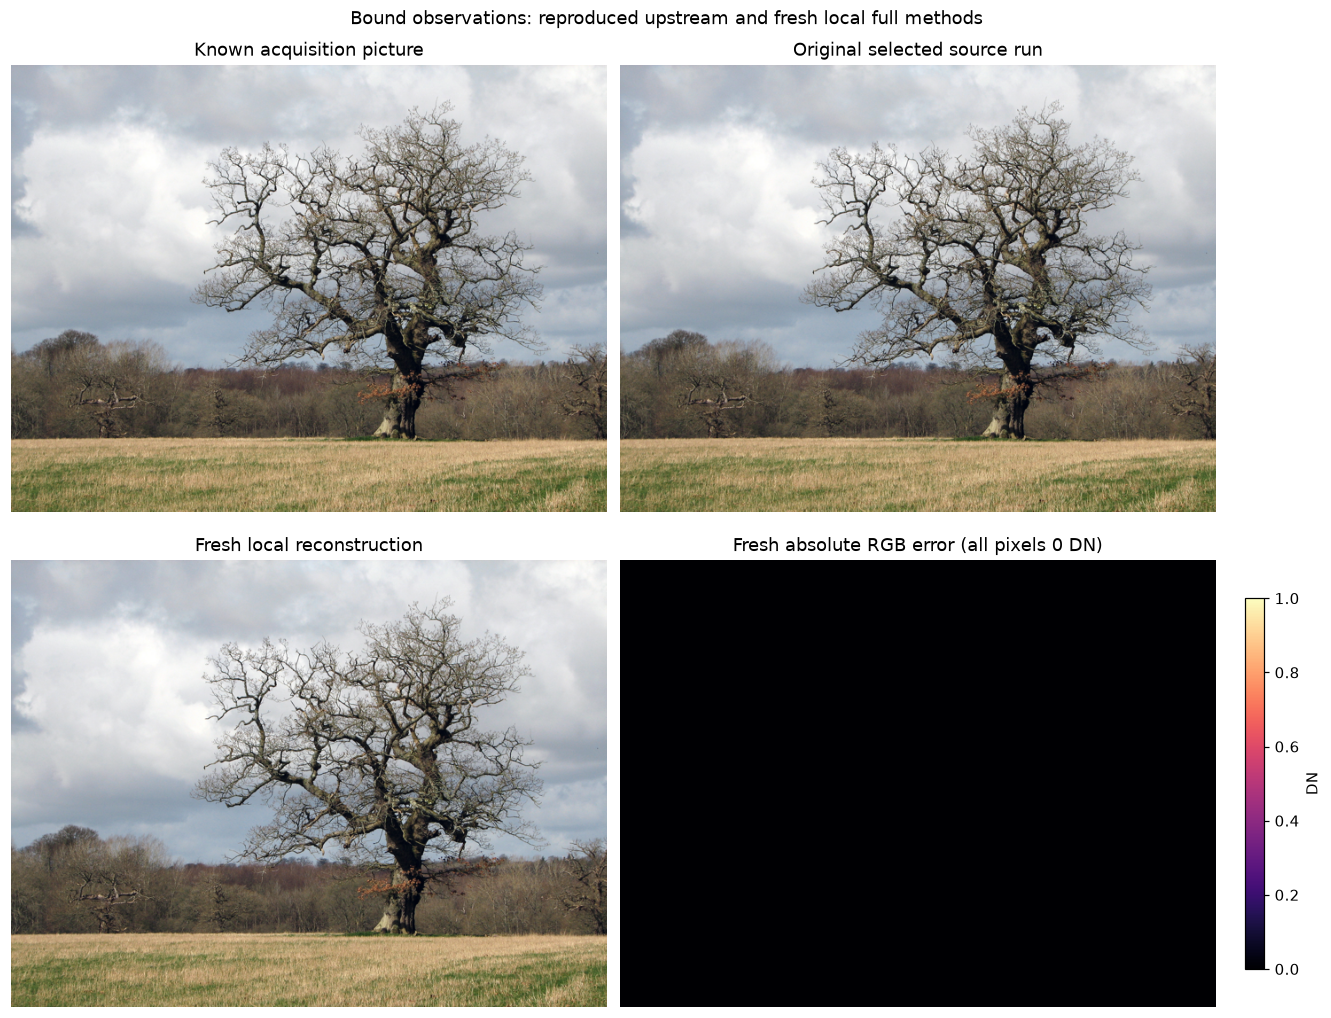

| Stage | Source joint | Fresh joint | Source oriented neighbor | Fresh oriented neighbor |
|---|---:|---:|---:|---:|
| 0 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |
| 1 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |
| 2 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |
| 3 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |
| 4 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |
| 5 | 1.000000 | 1.000000 | 1.000000 | 1.000000 |

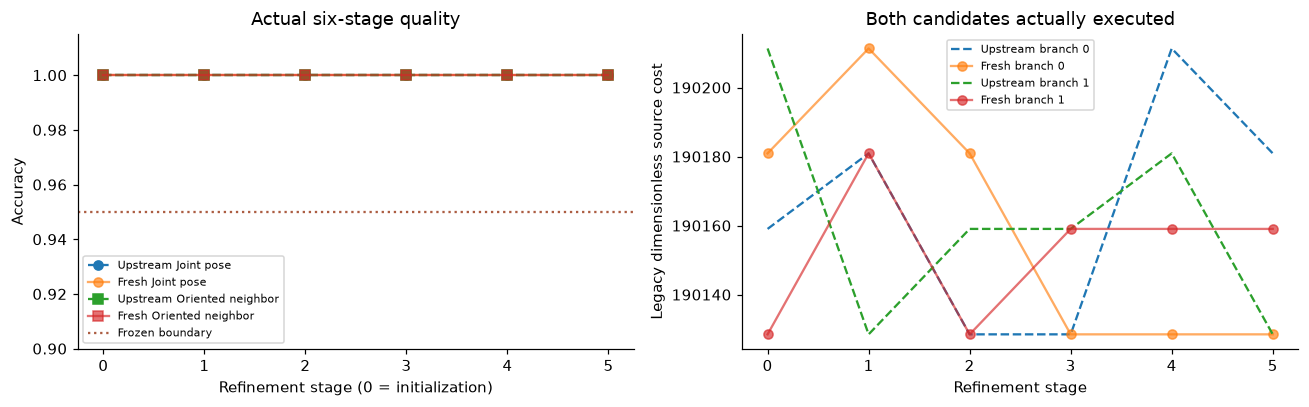

In [5]:
source_pose=(upstream['stage5_positions'][0],upstream['stage5_quarter_turns'][0])
fig,image_reports=plot_reconstructions(tiles,source_pose,(positions,quarter_turns),(truth_p,truth_q))
fig.suptitle('Bound observations: reproduced upstream and fresh local full methods',y=1.02)
plt.show()
rows=[]
for stage,h in enumerate(history):
    a=compare_poses(upstream[f'stage{stage}_positions'][0],upstream[f'stage{stage}_quarter_turns'][0],truth_p,truth_q)
    b=compare_poses(h['positions'],h['quarter_turns'],truth_p,truth_q)
    rows.append({'stage':stage,'source':a['metrics'],'fresh':b['metrics'],'source_costs':upstream[f'stage{stage}_candidate_costs'].tolist(),'fresh_costs':h['costs'].tolist()})
display(Markdown('| Stage | Source joint | Fresh joint | Source oriented neighbor | Fresh oriented neighbor |\n|---|---:|---:|---:|---:|\n'+'\n'.join(f"| {r['stage']} | {r['source']['joint_piece_accuracy']:.6f} | {r['fresh']['joint_piece_accuracy']:.6f} | {r['source']['oriented_neighbor_accuracy']:.6f} | {r['fresh']['oriented_neighbor_accuracy']:.6f} |" for r in rows)))
fig,ax=plt.subplots(1,2,figsize=(12,3.8))
for key,label,marker in [('joint_piece_accuracy','Joint pose','o'),('oriented_neighbor_accuracy','Oriented neighbor','s')]:
    ax[0].plot(range(6),[r['source'][key] for r in rows],marker=marker,ls='--',label='Upstream '+label)
    ax[0].plot(range(6),[r['fresh'][key] for r in rows],marker=marker,ls='-',alpha=.65,label='Fresh '+label)
ax[0].axhline(.95,color='#ac5d42',ls=':',label='Frozen boundary');ax[0].set(ylim=(.9,1.015),xlabel='Refinement stage (0 = initialization)',ylabel='Accuracy',title='Actual six-stage quality');ax[0].legend(fontsize=7)
for branch in range(2):
    ax[1].plot(range(6),[r['source_costs'][branch] for r in rows],ls='--',label=f'Upstream branch {branch}')
    ax[1].plot(range(6),[r['fresh_costs'][branch] for r in rows],marker='o',alpha=.65,label=f'Fresh branch {branch}')
ax[1].set(xlabel='Refinement stage',ylabel='Legacy dimensionless source cost',title='Both candidates actually executed');ax[1].legend(fontsize=7)
fig.tight_layout();plt.show()


The bound instance is already exactly assembled after initialization. The
five refinements are still executed; the flat quality trajectory reflects actual
measurements, rather than omitted iterations. Source and fresh orientations may
use different global gauges, which the declared common-C4 comparison removes.
Legacy candidate costs are retained as source diagnostics and are not relabeled
as an unbiased image error. The legacy boundary-counting cost is itself not
global-C4 invariant, so branch-cost trajectories need not agree when independent
singular modes choose different common orientations; physical pose comparison
uses the declared common-C4 convention instead.

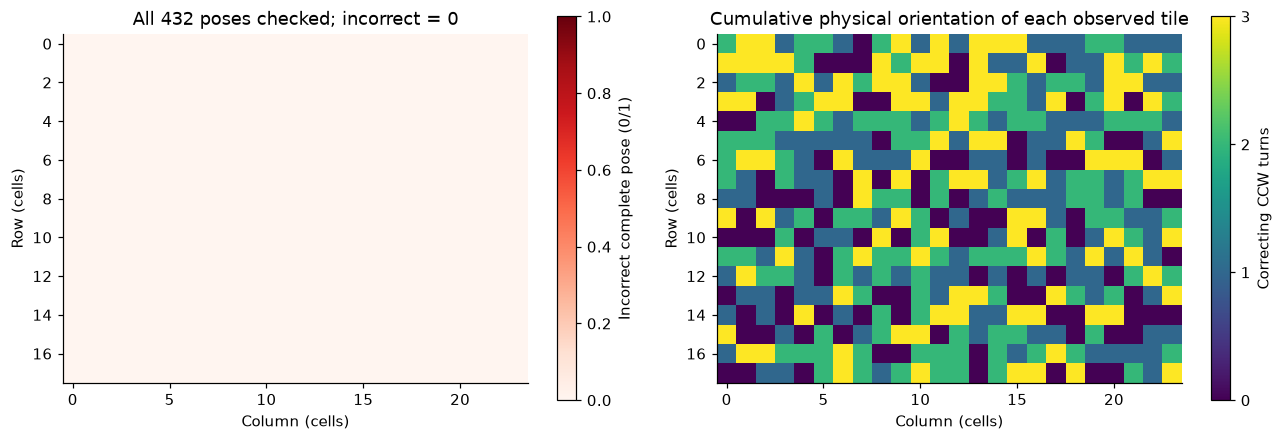

In [6]:
aligned_p=fresh_report['aligned_positions'];aligned_q=fresh_report['aligned_quarter_turns']
joint_ok=np.all(aligned_p==truth_p,axis=1)&(aligned_q==truth_q)
grid_error=np.zeros((18,24));grid_turn=np.zeros((18,24))
for i,(r,c) in enumerate(truth_p):grid_error[r,c]=not joint_ok[i];grid_turn[r,c]=aligned_q[i]
fig,ax=plt.subplots(1,2,figsize=(12,4))
a=ax[0].imshow(grid_error,cmap='Reds',vmin=0,vmax=1);fig.colorbar(a,ax=ax[0],label='Incorrect complete pose (0/1)')
ax[0].set(title=f'All 432 poses checked; incorrect = {np.count_nonzero(grid_error)}',xlabel='Column (cells)',ylabel='Row (cells)')
a=ax[1].imshow(grid_turn,cmap='viridis',vmin=0,vmax=3);fig.colorbar(a,ax=ax[1],ticks=[0,1,2,3],label='Correcting CCW turns')
ax[1].set(title='Cumulative physical orientation of each observed tile',xlabel='Column (cells)',ylabel='Row (cells)')
fig.tight_layout();plt.show()


## Evaluation stress controls

These are deliberate perturbations of the freshly computed submission, not
additional inverse reconstructions. They demonstrate why both coupled metrics
are required. Rotating fragments while preserving their positions can retain
position accuracy yet damage physical seams. Swapping positions leaves a valid
collision-free rectangle but breaks the target spatial relationships.

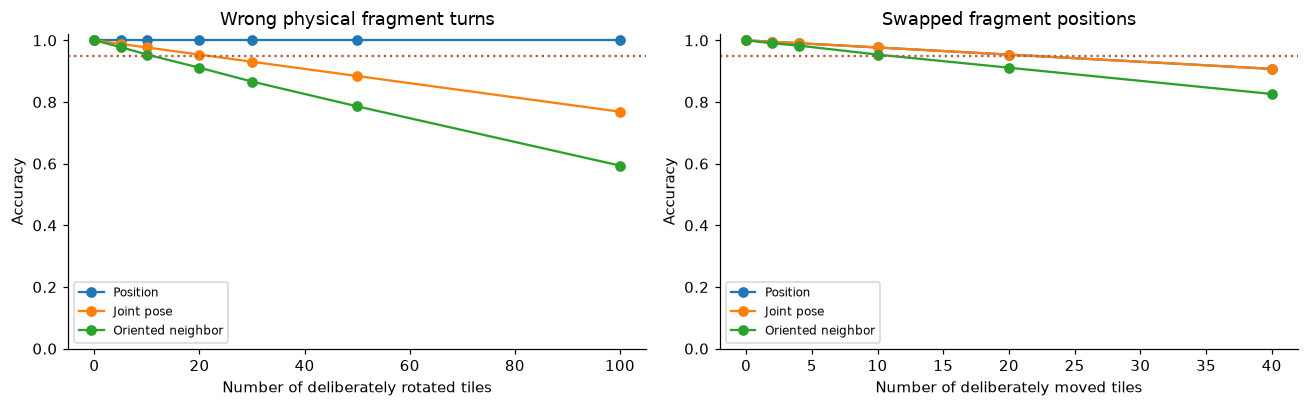

In [7]:
controls=[]
for count in [0,5,10,20,30,50,100]:
    q=quarter_turns.copy();q[:count]=(q[:count]+1)%4
    r=compare_poses(positions,q,truth_p,truth_q)
    controls.append((count,r['metrics']))
swap=[]
for count in [0,2,4,10,20,40]:
    p=positions.copy()
    for i in range(0,count,2):p[[i,i+1]]=p[[i+1,i]]
    swap.append((count,compare_poses(p,quarter_turns,truth_p,truth_q)['metrics']))
fig,ax=plt.subplots(1,2,figsize=(12,3.8))
for a,data,title,xlabel in [(ax[0],controls,'Wrong physical fragment turns','Number of deliberately rotated tiles'),(ax[1],swap,'Swapped fragment positions','Number of deliberately moved tiles')]:
    for key,label in [('position_accuracy','Position'),('joint_piece_accuracy','Joint pose'),('oriented_neighbor_accuracy','Oriented neighbor')]:
        a.plot([x for x,_ in data],[r[key] for _,r in data],marker='o',label=label)
    a.axhline(.95,color='#ac5d42',ls=':');a.set(xlabel=xlabel,ylabel='Accuracy',ylim=(0,1.02),title=title);a.legend(fontsize=8)
fig.tight_layout();plt.show()


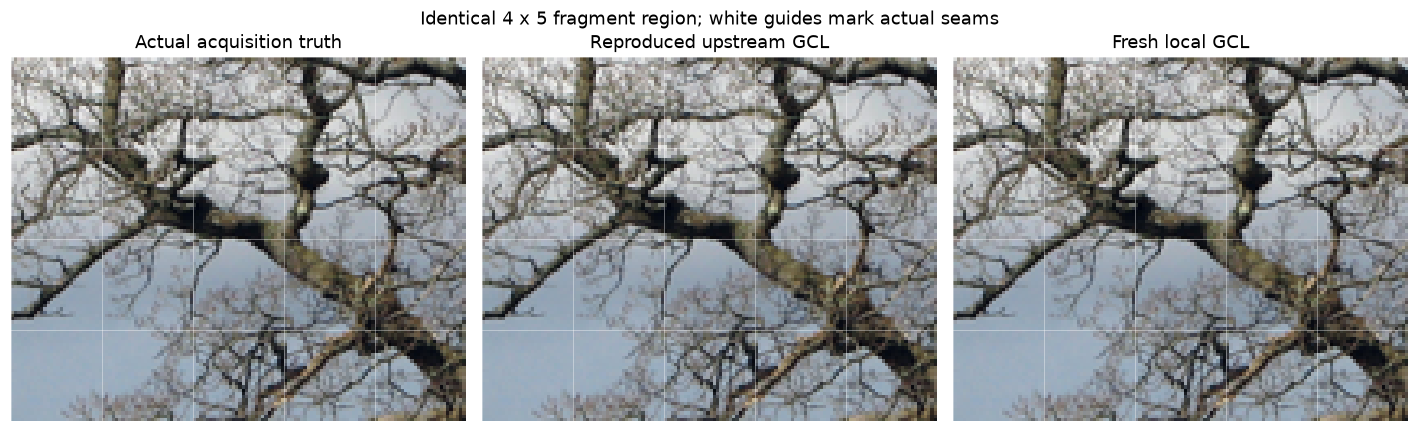

In [8]:
# Pixel-level seam review, same region and original scale in all groups.
source_result=compare_poses(*source_pose,truth_p,truth_q)
source_image=render_tiles(tiles,source_result['aligned_positions'],source_result['aligned_quarter_turns'])
region=(slice(196,308),slice(252,392))
fig,ax=plt.subplots(1,3,figsize=(13,4))
for a,image,label in zip(ax,[truth_image,source_image,fresh_image],['Actual acquisition truth','Reproduced upstream GCL','Fresh local GCL']):
    a.imshow(image[region].astype(float)/65535)
    for x in range(0,141,28):a.axvline(x-.5,color='white',alpha=.4,lw=.6)
    for y in range(0,113,28):a.axhline(y-.5,color='white',alpha=.4,lw=.6)
    a.set_title(label);a.set_axis_off()
fig.suptitle('Identical 4 x 5 fragment region; white guides mark actual seams')
fig.tight_layout();plt.show()


## Reproduced upstream method comparisons

Two additional author-provided methods were actually executed once on the same
frozen observations: Gallagher's greedy assembly and the full Yu type-2 method.
The Yu comparison retains all 1728 explicit rotation hypotheses, its score
modification, replica handling and original position/boundary budgets. It is not
the easier position stage after GCL has already supplied rotations.

These arrays are explicitly reproduced upstream comparisons, loaded for review;
the selected GCL reconstruction above was computed fresh locally. Ground truth
is used only for the common-C4 evaluation. Neither baseline can select a new
shuffle, stop on a true score, or repair its assembly with known positions.
Source-specific numerical compatibility and diagnostic annotation issues are
recorded in validation. Rendering uses the physical accumulated tile turns,
independently checked against the original baseline's actual image.

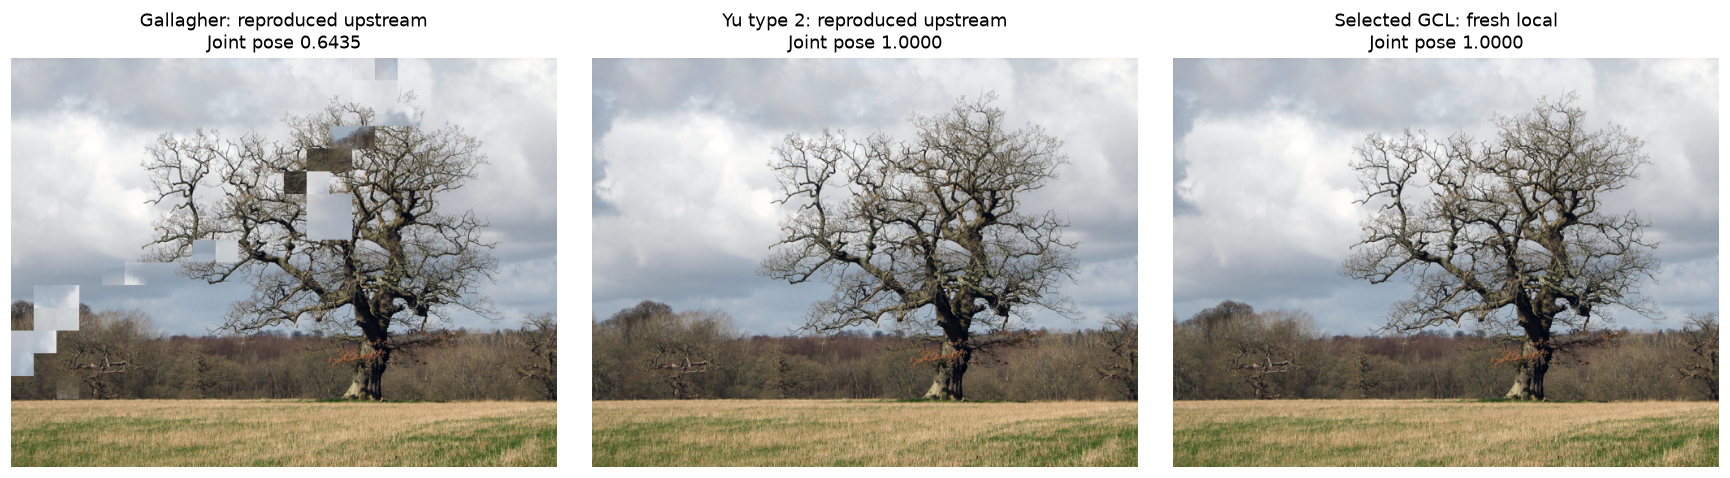

| Actual result group | Joint pose | Oriented neighbor | Position | Orientation | Image DR-NRMSE |
|---|---:|---:|---:|---:|---:|
| Gallagher: reproduced upstream | 0.643519 | 0.890511 | 0.643519 | 0.953704 | 0.110376 |
| Yu type 2: reproduced upstream | 1.000000 | 1.000000 | 1.000000 | 1.000000 | 0.000000 |
| Selected GCL: fresh local | 1.000000 | 1.000000 | 1.000000 | 1.000000 | 0.000000 |

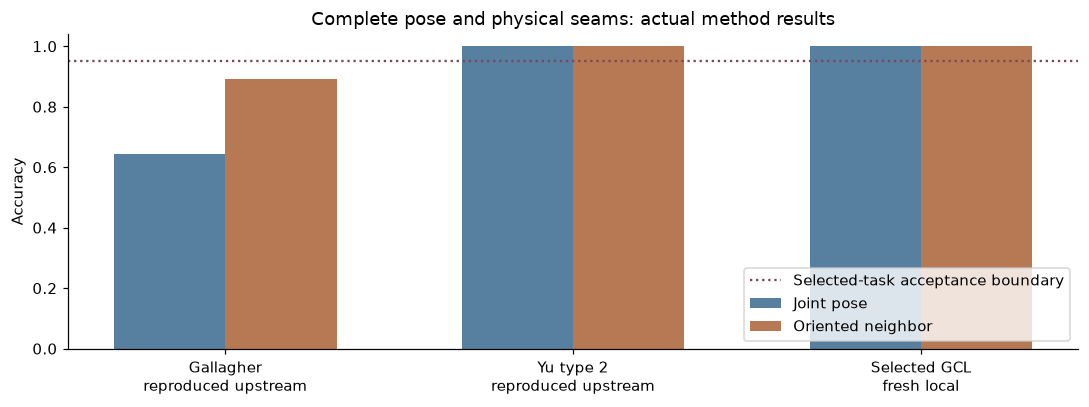

In [9]:
baseline_rows=[]
fig,ax=plt.subplots(1,3,figsize=(16,4.2))
for axis,name,title in zip(ax[:2],['gallagher','yu'],['Gallagher: reproduced upstream','Yu type 2: reproduced upstream']):
    with np.load(TASK/f'notebooks/reference_outputs/{name}_pose.npz',allow_pickle=False) as z:
        bp=z['positions'][0];bq=z['quarter_turns'][0]
        assert 'valid_mask' not in z.files or np.all(z['valid_mask'])
    br=compare_poses(bp,bq,truth_p,truth_q)
    bi=render_tiles(tiles,br['aligned_positions'],br['aligned_quarter_turns'])
    bn=dynamic_range_nrmse(bi,truth_image)
    baseline_rows.append({'method':title,'metrics':br['metrics'],'nrmse':bn})
    axis.imshow(bi.astype(float)/65535);axis.set_title(title+'\nJoint pose '+format(br['metrics']['joint_piece_accuracy'],'.4f'));axis.set_axis_off()
ax[2].imshow(fresh_image.astype(float)/65535);ax[2].set_title('Selected GCL: fresh local\nJoint pose '+format(fresh_report['metrics']['joint_piece_accuracy'],'.4f'));ax[2].set_axis_off()
fig.tight_layout();plt.show()
baseline_rows.append({'method':'Selected GCL: fresh local','metrics':fresh_report['metrics'],'nrmse':dynamic_range_nrmse(fresh_image,truth_image)})
display(Markdown('| Actual result group | Joint pose | Oriented neighbor | Position | Orientation | Image DR-NRMSE |\n|---|---:|---:|---:|---:|---:|\n'+'\n'.join(f"| {r['method']} | {r['metrics']['joint_piece_accuracy']:.6f} | {r['metrics']['oriented_neighbor_accuracy']:.6f} | {r['metrics']['position_accuracy']:.6f} | {r['metrics']['orientation_accuracy']:.6f} | {r['nrmse']:.6f} |" for r in baseline_rows)))
fig,ax=plt.subplots(figsize=(10,3.8))
x=np.arange(len(baseline_rows));width=.32
for offset,key,label,color in [(-width/2,'joint_piece_accuracy','Joint pose','#567fa0'),(width/2,'oriented_neighbor_accuracy','Oriented neighbor','#b77954')]:
    ax.bar(x+offset,[r['metrics'][key] for r in baseline_rows],width,label=label,color=color)
ax.axhline(.95,ls=':',color='#7f4654',label='Selected-task acceptance boundary')
ax.set_xticks(x,[r['method'].replace(': ','\n') for r in baseline_rows]);ax.set(ylabel='Accuracy',ylim=(0,1.04),title='Complete pose and physical seams: actual method results');ax.legend(loc='lower right')
fig.tight_layout();plt.show()


# 6. Conclusion

The full local method recovers a physically consistent discrete assembly on the
bound observations, with all five refinements actually executed. Comparisons
distinguish actual acquisition truth, reproduced upstream results and fresh
local reconstruction. The perfect bound result does not establish universal
success on arbitrary puzzles: repeated textures, symmetric tiles, missing
fragments and photometric changes require different identifiability conditions.
The observation-only audit found no exact C4-duplicate or rotationally symmetric
tiles in this bound dataset. The public target permits any method meeting the
same declared coupled pose quality, without exposing a particular solver path.